# Problem 1 RNN LSTM and GRU

BITS ID: **2026aj05054**

Chosen values: recurrent hidden size 48, Transformer width 96, seeds 7, 21 and 42. The language model uses four layers, four heads and context 128.


## Setup

**VS Code:** extract the full assignment ZIP, open its folder, install `requirements.txt` in your local Python 3.10 and select that kernel. **Colab:** upload this notebook through File > Upload notebook. Run All; when setup asks, upload the full assignment ZIP. Colab uses its installed packages and installs only missing ones. It trains afresh by default; local runs resume completed records. The experiment settings below are shared by both environments.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, random, json, math, time, csv, tempfile, copy, zipfile, urllib.request
import gc, resource, sys, subprocess, importlib.util, io

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Colab provides current packages; keep its working runtime instead of installing
# Python-3.10-only pins. Local installation uses requirements.txt before Run All.
if IN_COLAB:
    packages = {'torch':'torch>=2.5,<3', 'numpy':'numpy>=1.26',
                'pandas':'pandas>=2', 'matplotlib':'matplotlib>=3.9',
                'IPython':'ipython'}
    missing = [package for module,package in packages.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable,'-m','pip','install',*missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Image, FileLink

ASSIGNMENT_NAME = '2026aj05054_DNN_Assignment'
CURRENT_PROBLEM = 'problem1'

def find_assignment_root(start):
    start = Path(start).resolve()
    for parent in (start, *start.parents):
        for candidate in (parent, parent/ASSIGNMENT_NAME):
            required = ['requirements.txt', 'problem1/problem1.ipynb',
                        'problem2/problem2.ipynb']
            if all((candidate/name).is_file() for name in required):
                return candidate
    return None

def unpack_assignment_zip(archive):
    destination = Path(tempfile.mkdtemp(prefix='dnn-assignment-')).resolve()
    with zipfile.ZipFile(archive) as bundle:
        for member in bundle.infolist():
            target = (destination/member.filename).resolve()
            is_link = (member.external_attr >> 16) & 0o170000 == 0o120000
            if not target.is_relative_to(destination) or is_link or '\\' in member.filename:
                raise ValueError('ZIP contains a path outside its destination.')
        bundle.extractall(destination)
    candidates = {find_assignment_root(p.parent) for p in destination.rglob('problem1.ipynb')}
    candidates.discard(None)
    candidates = {root for root in candidates if root.is_relative_to(destination)}
    if len(candidates) != 1:
        raise ValueError('Upload the full assignment ZIP with both problem folders.')
    return candidates.pop()

ROOT = find_assignment_root(Path.cwd())
if ROOT is None and IN_COLAB:
    if '--context-worker' in sys.argv:
        raise FileNotFoundError('Profiling worker must start in the assignment folder.')
    archives = sorted(Path.cwd().glob(ASSIGNMENT_NAME+'*.zip'))
    if archives:
        ROOT = unpack_assignment_zip(archives[-1])
    else:
        print('Upload the complete assignment ZIP (not just this notebook).')
        uploaded = colab_files.upload()
        zipped = [data for name,data in uploaded.items() if name.lower().endswith('.zip')]
        if len(zipped) != 1:
            raise ValueError('Select exactly one complete assignment ZIP.')
        ROOT = unpack_assignment_zip(io.BytesIO(zipped[0]))
if ROOT is None:
    raise FileNotFoundError('Open the extracted assignment folder in VS Code, then Run All.')
os.chdir(ROOT)

DATA_DIR = ROOT.parent/'.dnn_data'
if (ROOT.parent/'.qa/data').is_dir():
    DATA_DIR = ROOT.parent/'.qa/data'
CACHE_DIR = ROOT.parent/'.dnn_model_cache'
if (ROOT.parent/'.qa/student_cache').is_dir():
    CACHE_DIR = ROOT.parent/'.qa/student_cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REUSE_COMPLETED_RUNS = not IN_COLAB  # Colab trains afresh; local runs resume by default.

if torch.cuda.is_available():
    accelerator = torch.device('cuda')
elif torch.backends.mps.is_available():
    accelerator = torch.device('mps')
else:
    accelerator = torch.device('cpu')

# A local benchmark found CPU faster for the RNN/GRU loops on this Mac.
# All HAR models use the same device so their epoch times are comparable.
USE_ACCELERATOR_FOR_RECURRENT = False
har_device = accelerator if USE_ACCELERATOR_FOR_RECURRENT else torch.device('cpu')
config = SimpleNamespace(
    ROOT=ROOT, DATA_DIR=DATA_DIR, CACHE_DIR=CACHE_DIR,
    RESULTS_PATH=ROOT/'results.csv', STUDENT_ID='2026aj05054',
    STUDENT_NAME='Ganga Maheshwar Reddy Yeddula',
    SEEDS=(7,21,42), HIDDEN_SIZE=48, MODEL_DIM=96, HEADS=4, LAYERS=4,
    CONTEXT=128, BATCH_SIZE=128, LM_BATCH_SIZE=32, HAR_EPOCHS=8,
    ADDING_EPOCHS=12, LM_STEPS=600, LR=0.001, DROPOUT=0.1, THREADS=2,
    ACCELERATOR=accelerator, HAR_DEVICE=har_device, LM_DEVICE=accelerator,
    DEVICE=har_device, REUSE_COMPLETED_RUNS=REUSE_COMPLETED_RUNS)
cfg = config
torch.set_num_threads(config.THREADS)
print('PyTorch:', torch.__version__)
print('Available accelerator:', accelerator)
print('HAR/recurrent device:', config.HAR_DEVICE)
print('Transformer language-model device:', config.LM_DEVICE)
print('Environment:', 'Colab' if IN_COLAB else 'VS Code / local Python')
print('Reuse completed runs:', config.REUSE_COMPLETED_RUNS)
NOTEBOOK_STARTED = time.perf_counter()


PyTorch: 2.5.1
Available accelerator: mps
HAR/recurrent device: cpu
Transformer language-model device: mps
Environment: VS Code / local Python
Reuse completed runs: True


## Seeds metrics and result recording

The classification metrics use NumPy so they do not import SciPy. Results are written after each completed run.


In [2]:
COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
           "test_mse", "params", "sec_per_epoch", "val_loss_nats",
           "bits_per_char", "notes"]

def _classification_targets(y_true, y_pred):
    """Validate the one-dimensional, nonempty label vectors used by this task."""
    true, predicted = np.asarray(y_true), np.asarray(y_pred)
    if true.ndim != 1 or predicted.ndim != 1 or true.shape != predicted.shape:
        raise ValueError('Expected matching one-dimensional classification targets.')
    if true.size == 0:
        raise ValueError('Classification metrics require at least one example.')
    return true, predicted


def accuracy_score(y_true, y_pred):
    """Fraction of correctly classified examples, without a SciPy dependency."""
    true, predicted = _classification_targets(y_true, y_pred)
    return float(np.mean(true == predicted))


def confusion_matrix(y_true, y_pred, labels=None):
    """Integer count matrix, with true classes on rows and predictions on columns."""
    true, predicted = _classification_targets(y_true, y_pred)
    selected = (np.unique(np.concatenate([true, predicted]))
                if labels is None else np.asarray(labels))
    if selected.ndim != 1 or selected.size == 0 or len(set(selected.tolist())) != len(selected):
        raise ValueError('labels must be a nonempty sequence of distinct classes.')
    positions = {label: index for index, label in enumerate(selected.tolist())}
    matrix = np.zeros((len(selected), len(selected)), dtype=np.int64)
    for actual, prediction in zip(true.tolist(), predicted.tolist()):
        if actual in positions and prediction in positions:
            matrix[positions[actual], positions[prediction]] += 1
    return matrix


def f1_score(y_true, y_pred, *, labels=None, average='macro', zero_division=0):
    """Macro F1 for the assignment; absent classes follow zero_division=0 or 1.

    Count each class against the full target vectors. This preserves false
    positives/negatives when an explicit label list selects only some classes.
    """
    if average != 'macro' or zero_division not in (0, 1):
        raise ValueError('This helper supports macro F1 and zero_division 0 or 1.')
    true, predicted = _classification_targets(y_true, y_pred)
    selected = (np.unique(np.concatenate([true, predicted]))
                if labels is None else np.asarray(labels))
    if selected.ndim != 1 or selected.size == 0 or len(set(selected.tolist())) != len(selected):
        raise ValueError('labels must be a nonempty sequence of distinct classes.')
    scores = []
    for label in selected:
        actual_positive, predicted_positive = true == label, predicted == label
        true_positives = int(np.count_nonzero(actual_positive & predicted_positive))
        denominator = int(np.count_nonzero(actual_positive) + np.count_nonzero(predicted_positive))
        scores.append(2.0 * true_positives / denominator if denominator else float(zero_division))
    return float(np.mean(scores))


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def append_result(**kwargs):
    """Save after each run. Sequential writers only; reruns replace an identity."""
    unknown = set(kwargs) - set(COLUMNS)
    if unknown:
        raise ValueError(f"Unexpected results columns: {sorted(unknown)}")
    row = {key: "" if kwargs.get(key) is None else str(kwargs.get(key, ""))
           for key in COLUMNS}
    for key in COLUMNS[4:11]:
        if row[key] and not math.isfinite(float(row[key])):
            raise ValueError(f"Non-finite {key}; record the failed run separately.")
    if row["val_loss_nats"] and row["bits_per_char"]:
        assert math.isclose(float(row["bits_per_char"]),
                            float(row["val_loss_nats"]) / math.log(2), rel_tol=1e-6)
    path = Path(config.RESULTS_PATH)
    path.parent.mkdir(parents=True, exist_ok=True)
    old = []
    if path.exists():
        with path.open(newline="", encoding="utf-8") as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != COLUMNS:
                raise ValueError("Existing results.csv schema differs from assignment.")
            old = list(reader)
    keys = ("problem", "model", "seed", "seq_len", "notes")
    identity = tuple(row[key] for key in keys)
    old = [r for r in old if tuple(r[key] for key in keys) != identity]
    old.append(row)
    fd, temporary = tempfile.mkstemp(dir=path.parent, prefix=".results-", suffix=".csv")
    try:
        with os.fdopen(fd, "w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=COLUMNS)
            writer.writeheader()
            writer.writerows(old)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        if Path(temporary).exists():
            Path(temporary).unlink()


def begin_problem_run(problem):
    """Fresh training replaces this problem's rows, preserving the other problem."""
    if config.REUSE_COMPLETED_RUNS:
        return
    path = ROOT/'results.csv'
    if path.exists():
        with path.open(newline='',encoding='utf-8') as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != COLUMNS:
                raise ValueError('Existing results.csv has a different schema.')
            kept = [row for row in reader if row['problem'] != 'P'+problem[-1]]
        with tempfile.NamedTemporaryFile('w',newline='',encoding='utf-8',
                                         dir=path.parent,delete=False) as stream:
            writer = csv.DictWriter(stream,fieldnames=COLUMNS)
            writer.writeheader(); writer.writerows(kept)
            temporary = stream.name
        os.replace(temporary,path)
    (ROOT/problem/'figures/notebook_runtime.json').unlink(missing_ok=True)

def finish_notebook_run():
    """Wall time from the end of setup through the final displayed results."""
    elapsed = time.perf_counter()-NOTEBOOK_STARTED
    record = {'problem':CURRENT_PROBLEM, 'elapsed_seconds':elapsed,
              'environment':'colab' if IN_COLAB else 'local',
              'reuse_completed_runs':config.REUSE_COMPLETED_RUNS,
              'python':sys.version.split()[0], 'torch':torch.__version__,
              'numpy':np.__version__, 'completed_at_unix':time.time(),
              'cuda_device_name':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
              'scope':'Setup excluded; includes definitions, tests, downloads, experiments, figures and samples. Cached replay is included when reuse is true.'}
    target = ROOT/CURRENT_PROBLEM/'figures/notebook_runtime.json'
    target.write_text(json.dumps(record,indent=2))
    print(f'Notebook elapsed: {elapsed/60:.2f} minutes. Runtime record: {target.relative_to(ROOT)}')
    if config.REUSE_COMPLETED_RUNS:
        print('This invocation allowed cached results; it is not a full-training benchmark.')

def export_run_files():
    """Save a portable ZIP; in Colab, first supply the executed UI notebook."""
    if IN_COLAB:
        print('First use File > Download > Download .ipynb. Then upload that executed notebook here.')
        uploaded = colab_files.upload()
        notebooks = [data for name,data in uploaded.items() if name.endswith('.ipynb')]
        if len(notebooks) != 1:
            raise ValueError('Upload exactly one executed notebook.')
        notebook = json.loads(notebooks[0])
        title = ''.join(notebook['cells'][0]['source'])
        if 'Problem '+CURRENT_PROBLEM[-1] not in title:
            raise ValueError('Upload the notebook for '+CURRENT_PROBLEM+'.')
        for cell in notebook['cells']:
            if cell['cell_type']=='code' and ''.join(cell['source']).strip():
                if cell.get('execution_count') is None or any(o.get('output_type')=='error' for o in cell.get('outputs',[])):
                    raise ValueError('Run all cells successfully and save outputs before exporting.')
        (ROOT/CURRENT_PROBLEM/(CURRENT_PROBLEM+'.ipynb')).write_bytes(notebooks[0])
    output = ROOT.parent/(ASSIGNMENT_NAME+'.zip')
    required = ['README.md','requirements.txt','report.pdf','results.csv',
                'problem1/problem1.ipynb','problem2/problem2.ipynb',
                'problem2/generated_samples.txt']
    with zipfile.ZipFile(output,'w',zipfile.ZIP_DEFLATED) as bundle:
        for relative in required:
            bundle.write(ROOT/relative,ASSIGNMENT_NAME+'/'+relative)
        for problem in ('problem1','problem2'):
            for path in sorted((ROOT/problem/'figures').rglob('*')):
                if path.is_file() and path.suffix in {'.png','.csv','.json','.txt'}:
                    if not any(part.startswith('.') for part in path.relative_to(ROOT).parts):
                        bundle.write(path,ASSIGNMENT_NAME+'/'+path.relative_to(ROOT).as_posix())
    if output.stat().st_size > 25_000_000:
        raise ValueError('Export exceeds the assignment 25 MB limit.')
    print('Saved',output.name,'- update report prose if rerun measurements changed.')
    if IN_COLAB:
        colab_files.download(str(output))
    else:
        display(FileLink(str(output)))
    return output


In [3]:
HERE = Path(config.ROOT) / "problem1"

RESULTS_PATH = Path(config.RESULTS_PATH)

FIGURES = HERE / "figures"

ARTIFACTS = FIGURES

_HAR_RAW_CACHE = None

_HAR_SPLIT_CACHE = {}

CHANNELS = (
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
)

CLASSES = ("Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying")

MODELS = ("RNN", "LSTM", "GRU")


## Adding data

Each sequence has one marker in each half; the target adds the two marked values.


In [4]:
def make_adding(n, T, seed):
    """The assignment's generator, reproduced without changing its RNG order."""
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)


In [5]:
def test_adding_generator():
    for length in (50, 100, 200, 400):
        x, y = make_adding(64, length, 0)
        assert x.shape == (64, length, 2) and y.shape == (64,)
        assert x.dtype == y.dtype == np.float32
        assert np.all(x[:, :, 1].sum(axis=1) == 2)
        assert np.all(x[:, :length // 2, 1].sum(axis=1) == 1)
        assert np.all(x[:, length // 2:, 1].sum(axis=1) == 1)
        assert np.allclose(y, (x[:, :, 0] * x[:, :, 1]).sum(axis=1))
        x2, y2 = make_adding(64, length, 0)
        assert np.array_equal(x, x2) and np.array_equal(y, y2)


In [6]:
test_adding_generator()
assert make_adding(4,50,0)[0].shape == (4,50,2)
print('Adding generator tests passed.')


Adding generator tests passed.


## HAR data

Four training subjects are held out for validation for each seed. Normalisation uses the remaining training subjects only.


In [7]:
def _extract_zip_safely(archive, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination):
                raise ValueError("Archive contains a path outside the data directory")
        zf.extractall(destination)


def har_directory():
    """Download the official archive once, including its nested ZIP if present."""
    data = Path(config.DATA_DIR)
    data.mkdir(parents=True, exist_ok=True)
    candidates = list(data.rglob("UCI HAR Dataset/train/y_train.txt"))
    if not candidates:
        archive = data / "har.zip"
        if not archive.exists():
            urllib.request.urlretrieve(
                "https://archive.ics.uci.edu/static/public/240/"
                "human+activity+recognition+using+smartphones.zip", archive,
            )
        _extract_zip_safely(archive, data / "har")
        for nested in (data / "har").rglob("*.zip"):
            _extract_zip_safely(nested, nested.parent)
        candidates = list(data.rglob("UCI HAR Dataset/train/y_train.txt"))
    if len(candidates) != 1:
        raise RuntimeError(f"Expected one HAR directory, found {len(candidates)}")
    return candidates[0].parents[1]


def load_har(seed):
    """Subject-wise split and channel scaling fitted on the training part only."""
    global _HAR_RAW_CACHE
    if seed in _HAR_SPLIT_CACHE:
        return _HAR_SPLIT_CACHE[seed]
    if _HAR_RAW_CACHE is None:
        directory = har_directory()
        arrays = {}
        for split, count in (("train", 7352), ("test", 2947)):
            arrays[split] = np.stack([
                np.loadtxt(directory / split / "Inertial Signals" / f"{c}_{split}.txt",
                           dtype=np.float32) for c in CHANNELS
            ], axis=-1)
            assert arrays[split].shape == (count, 128, 9)
            arrays[f"y_{split}"] = np.loadtxt(
                directory / split / f"y_{split}.txt", dtype=np.int64,
            ) - 1
            arrays[f"s_{split}"] = np.loadtxt(
                directory / split / f"subject_{split}.txt", dtype=np.int64,
            )
        _HAR_RAW_CACHE = arrays
    arrays = _HAR_RAW_CACHE
    subjects = np.unique(arrays["s_train"])
    assert len(subjects) == 21 and len(np.unique(arrays["s_test"])) == 9
    assert not np.intersect1d(subjects, arrays["s_test"]).size
    val_subjects = np.random.default_rng(seed).choice(subjects, 4, replace=False)
    is_val = np.isin(arrays["s_train"], val_subjects)
    train_part = arrays["train"][~is_val]
    mean = train_part.mean(axis=(0, 1), dtype=np.float64).astype(np.float32)
    std = train_part.std(axis=(0, 1), dtype=np.float64).astype(np.float32)
    std = np.maximum(std, np.finfo(np.float32).eps)
    result = {
        "x_train": torch.from_numpy((train_part - mean) / std),
        "y_train": torch.from_numpy(arrays["y_train"][~is_val]),
        "x_val": torch.from_numpy((arrays["train"][is_val] - mean) / std),
        "y_val": torch.from_numpy(arrays["y_train"][is_val]),
        "x_test": torch.from_numpy((arrays["test"] - mean) / std),
        "y_test": torch.from_numpy(arrays["y_test"]),
        "train_subjects": subjects[~np.isin(subjects, val_subjects)].tolist(),
        "val_subjects": val_subjects.tolist(),
        "test_subjects": np.unique(arrays["s_test"]).tolist(),
        "mean": mean.tolist(), "std": std.tolist(),
    }
    assert len(result["train_subjects"]) == 17 and len(result["val_subjects"]) == 4
    assert not set(result["train_subjects"]) & set(result["val_subjects"])
    assert result["x_train"].shape[0] + result["x_val"].shape[0] == 7352
    assert torch.allclose(result["x_train"].mean((0, 1)), torch.zeros(9), atol=2e-4)
    assert torch.allclose(result["x_train"].std((0, 1), unbiased=False),
                          torch.ones(9), atol=2e-4)
    _HAR_SPLIT_CACHE[seed] = result
    return result


In [8]:
data = load_har(config.SEEDS[0])
assert data['x_test'].shape == (2947,128,9)
assert set(data['train_subjects']).isdisjoint(data['val_subjects'])
assert set(data['train_subjects']+data['val_subjects']).isdisjoint(data['test_subjects'])
print('HAR split and normalisation tests passed.')


HAR split and normalisation tests passed.


## Cells from equations

The four parameter names match the library weight-copy check. LSTM gates are ordered i/f/g/o; GRU gates are r/z/n.


In [9]:
class _MatrixCell(nn.Module):
    """Shared weight and bias parameters for a recurrent cell."""
    gates = 1

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size, self.hidden_size = input_size, hidden_size
        self.weight_ih = nn.Parameter(torch.empty(self.gates * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(self.gates * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(self.gates * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(self.gates * hidden_size))
        bound = 1.0 / math.sqrt(hidden_size)
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)


In [10]:
def check_cell(cell_type, kind):
    seed_all(123)
    batch, steps, inputs, hidden = 4, 9, 9, config.HIDDEN_SIZE
    library = getattr(nn,kind)(inputs,hidden,batch_first=True).cpu().eval()
    cell = cell_type(inputs,hidden).cpu().eval()
    with torch.no_grad():
        for name in ('weight_ih','weight_hh','bias_ih','bias_hh'):
            getattr(cell,name).copy_(getattr(library,name+'_l0'))
    x=torch.randn(batch,steps,inputs)
    h0,c0=torch.randn(1,batch,hidden),torch.randn(1,batch,hidden)
    expected,last=library(x,(h0,c0) if kind=='LSTM' else h0)
    state=(h0[0],c0[0]) if kind=='LSTM' else h0[0]
    values=[]
    for t in range(steps):
        state=cell(x[:,t],state)
        values.append(state[0] if kind=='LSTM' else state)
    error=float((torch.stack(values,1)-expected).abs().max().detach())
    assert error<1e-5
    if kind=='LSTM':
        assert torch.allclose(state[0],last[0][0],atol=1e-5)
        assert torch.allclose(state[1],last[1][0],atol=1e-5)
    else:
        assert torch.allclose(state,last[0],atol=1e-5)
    return error


### RNN cell


In [11]:
class MyRNNCell(_MatrixCell):
    """x [B,d], h [B,h] -> next hidden [B,h]."""
    def forward(self, x, h):
        return torch.tanh(x @ self.weight_ih.T + self.bias_ih
                          + h @ self.weight_hh.T + self.bias_hh)


In [12]:
error=check_cell(MyRNNCell,'RNN')
assert error<1e-5
print('RNN maximum error:',error)


RNN maximum error: 1.1920928955078125e-07


### LSTM cell


In [13]:
class MyLSTMCell(_MatrixCell):
    gates = 4

    def forward(self, x, state):
        # x [B,d]; h,c [B,h]; concatenated gate affine [B,4h].
        h, c = state
        affine = x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh
        i, f, g, o = affine.chunk(4, dim=-1)  # PyTorch gate order i,f,g,o.
        next_c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        next_h = torch.sigmoid(o) * torch.tanh(next_c)
        return next_h, next_c


In [14]:
error=check_cell(MyLSTMCell,'LSTM')
assert error<1e-5
print('LSTM maximum error:',error)


LSTM maximum error: 8.940696716308594e-08


### GRU cell


In [15]:
class MyGRUCell(_MatrixCell):
    gates = 3

    def forward(self, x, h):
        # Each input/hidden affine [B,3h], ordered reset,update,new.
        input_r, input_z, input_n = (x @ self.weight_ih.T + self.bias_ih).chunk(3, dim=-1)
        hidden_r, hidden_z, hidden_n = (h @ self.weight_hh.T + self.bias_hh).chunk(3, dim=-1)
        reset = torch.sigmoid(input_r + hidden_r)
        update = torch.sigmoid(input_z + hidden_z)
        candidate = torch.tanh(input_n + reset * hidden_n)  # Reset after hidden affine.
        return (1.0 - update) * candidate + update * h


In [16]:
error=check_cell(MyGRUCell,'GRU')
assert error<1e-5
print('GRU maximum error:',error)


GRU maximum error: 2.384185791015625e-07


## Training and diagnostics

All three main models use hidden size 48, Adam at 0.001, batch 128 and equal epoch budgets. The adding data are fixed across model seeds.


In [17]:
def _device_tag():
    return str(config.DEVICE).replace(':', '')


In [18]:
def _run_tag(name):
    return f'{name}_{_device_tag()}'


In [19]:
class RecurrentModel(nn.Module):
    """One permitted library layer and a last-hidden-state prediction head."""
    def __init__(self, kind, input_size, hidden_size, output_size):
        super().__init__()
        self.kind = kind
        self.hidden_size = hidden_size
        self.recurrent = getattr(nn, kind)(input_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x: [batch, time, input]; final h: [1, batch, hidden].
        _, state = self.recurrent(x)
        h = state[0] if self.kind == "LSTM" else state
        return self.head(h[-1])


In [20]:
def test_library_models():
    for kind in MODELS:
        model = RecurrentModel(kind, 9, 48, 6)
        assert model(torch.randn(3, 128, 9)).shape == (3, 6)
        layer_expected = {"RNN": 2832, "LSTM": 11328, "GRU": 8496}[kind]
        assert sum(p.numel() for p in model.recurrent.parameters()) == layer_expected
        assert sum(p.numel() for p in model.parameters()) == layer_expected + 48 * 6 + 6


In [21]:
def _sync():
    if str(config.DEVICE).startswith("cuda"):
        torch.cuda.synchronize()
    elif str(config.DEVICE).startswith("mps"):
        torch.mps.synchronize()


In [22]:
def _loader(x, y, seed, shuffle):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(x, y), batch_size=config.BATCH_SIZE,
                      shuffle=shuffle, generator=generator, num_workers=0)


In [23]:
@torch.no_grad()
def evaluate(model, loader, task):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum") if task == "har" else nn.MSELoss(reduction="sum")
    total, seen, labels, predictions = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(config.DEVICE), y.to(config.DEVICE)
        pred = model(x)
        if task == "adding":
            pred = pred.squeeze(-1)
        total += float(loss_fn(pred, y))
        seen += len(y)
        labels.extend(y.cpu().tolist())
        predictions.extend((pred.argmax(-1) if task == "har" else pred).cpu().tolist())
    result = {"loss": total / seen}
    if task == "har":
        result.update(acc=accuracy_score(labels, predictions),
                      f1=f1_score(labels, predictions, labels=list(range(6)),
                                  average="macro", zero_division=0),
                      confusion=confusion_matrix(labels, predictions, labels=list(range(6))).tolist())
    return result


In [24]:
def train(model, x_train, y_train, x_val, y_val, task, epochs, seed, clip=1.0):
    """Equal fixed budgets; retain the minimum-validation-loss epoch in memory."""
    model.to(config.DEVICE)
    train_loader = _loader(x_train, y_train, seed, True)
    val_loader = _loader(x_val, y_val, seed, False)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.LR)
    criterion = nn.CrossEntropyLoss() if task == "har" else nn.MSELoss()
    best_loss, best_state, history = math.inf, None, []
    for epoch in range(1, epochs + 1):
        model.train()
        total, seen = 0.0, 0
        _sync()
        start = time.perf_counter()
        for x, y in train_loader:
            x, y = x.to(config.DEVICE), y.to(config.DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred = model(x)
            if task == "adding":
                pred = pred.squeeze(-1)
            loss = criterion(pred, y)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite loss; record failure and inspect the run")
            loss.backward()
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            total += float(loss.detach()) * len(y)
            seen += len(y)
        _sync()
        seconds = time.perf_counter() - start  # training epoch only, excluding validation
        val = evaluate(model, val_loader, task)
        history.append({"epoch": epoch, "train_loss": total / seen,
                        "val_loss": val["loss"], "train_seconds": seconds})
        if val["loss"] < best_loss:
            best_loss = val["loss"]
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return history


In [25]:
def hidden_gradient_norms(model, x, y):
    """Measure d(mean MSE)/dh_t through actual PyTorch cell outputs.

    Index t denotes the hidden state after consuming input t (1-based in plots).
    Do not measure a detached stack of hidden states: it is not on the loss path.
    LSTM also carries c_t, so h-only gradients are not its complete memory story.
    """
    model.eval()
    cell = getattr(nn, model.kind + "Cell")(2, model.hidden_size).to(config.DEVICE)
    layer = model.recurrent
    with torch.no_grad():
        for name in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
            getattr(cell, name).copy_(getattr(layer, name + "_l0"))
    x, y = x.to(config.DEVICE), y.to(config.DEVICE)
    h = torch.zeros(len(x), model.hidden_size, device=config.DEVICE)
    c = torch.zeros_like(h)
    states = []
    model.zero_grad(set_to_none=True)
    for step in range(x.shape[1]):
        if model.kind == "LSTM":
            h, c = cell(x[:, step], (h, c))
        else:
            h = cell(x[:, step], h)
        h.retain_grad()
        states.append(h)
    nn.MSELoss()(model.head(h).squeeze(-1), y).backward()
    norms = np.asarray([float(state.grad.norm().cpu()) for state in states])
    # Sanity: the unrolled framework cells and the fused library layer agree.
    with torch.no_grad():
        direct = model(x)
        unrolled = model.head(h)
        assert torch.allclose(direct, unrolled, atol=1e-5, rtol=1e-5)
    return norms


In [26]:
def _record(tag, history, detail):
    ARTIFACTS.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(history).to_csv(ARTIFACTS / f"{tag}_history.csv", index=False)
    detail = {"status": "complete", **detail}
    target = ARTIFACTS / f"{tag}.json"
    temporary = target.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(detail, indent=2), encoding="utf-8")
    temporary.replace(target)


In [27]:
def _validate_experiment_settings():
    assert config.HIDDEN_SIZE == 48 and tuple(config.SEEDS) == (7, 21, 42)
    assert config.HAR_EPOCHS == 8 and config.ADDING_EPOCHS == 12
    assert config.BATCH_SIZE == 128 and config.LR == 1e-3
    FIGURES.mkdir(parents=True, exist_ok=True)
    ARTIFACTS.mkdir(parents=True, exist_ok=True)


In [28]:
def plot_class_balance(data, seed):
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(8, 3))
    positions = np.arange(6)
    for offset, split in enumerate(("train", "val", "test")):
        counts = torch.bincount(data[f"y_{split}"], minlength=6).numpy()
        ax.bar(positions + (offset - 1) * 0.25, counts, 0.25, label=split)
    ax.set(xticks=positions, xticklabels=CLASSES, ylabel="Windows",
           title=f"HAR class balance, subject split seed {seed}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / f"class_balance_seed{seed}.png", dpi=180)
    plt.close(fig)


In [29]:
def _notes(task, hidden, epochs, clip=1.0):
    clip_label = 'none' if clip is None else f'{clip:g}'
    return (f'task={task};h={hidden};epochs={epochs};clip={clip_label};'
            f'lr={config.LR};device={config.DEVICE};torch={torch.__version__};cache=1;batch={config.BATCH_SIZE}')


In [30]:
def _complete(tag, notes, gradients=False):
    if not getattr(config, 'REUSE_COMPLETED_RUNS', True):
        return None
    target = ARTIFACTS / f'{tag}.json'
    history = ARTIFACTS / f'{tag}_history.csv'
    if not target.exists() or not history.exists():
        return None
    if gradients and not (ARTIFACTS / f'{tag}_gradients.csv').exists():
        return None
    detail = json.loads(target.read_text(encoding='utf-8'))
    if detail.get('status') != 'complete' or detail['row']['notes'] != notes:
        return None
    frame = pd.read_csv(history)
    expected_epochs = int(notes.split(';epochs=')[1].split(';')[0])
    if len(frame) != expected_epochs or frame[['train_loss','val_loss','train_seconds']].isna().any().any():
        return None
    append_result(**detail['row'])
    print('RESUME complete:', tag, flush=True)
    return detail


In [31]:
def _base_row(kind, seed, length, model, history, notes):
    return dict(problem='P1', model=kind, seed=seed, seq_len=length,
                params=sum(p.numel() for p in model.parameters()),
                sec_per_epoch=float(np.mean([v['train_seconds'] for v in history])),
                notes=notes)


In [32]:
def _confusion_figure(records):
    best_kind = min(MODELS, key=lambda k: np.mean([
        r['validation']['loss'] for r in records if r['row']['model'] == k]))
    best = min((r for r in records if r['row']['model'] == best_kind),
               key=lambda r: r['validation']['loss'])
    matrix = np.asarray(best['test']['confusion'])
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap='Blues')
    for i in range(6):
        for j in range(6):
            ax.text(j, i, str(matrix[i,j]), ha='center', va='center',
                    color='white' if matrix[i,j] > matrix.max()/2 else 'black')
    ax.set(xticks=range(6), yticks=range(6), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='Predicted', ylabel='True',
           title=f'Validation-selected {best_kind}, seed {best["row"]["seed"]}')
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(FIGURES/'best_har_confusion.png', dpi=180)
    plt.close(fig)
    (ARTIFACTS/'best_har_model.json').write_text(json.dumps({
        'selection_rule':'minimum mean validation loss by family, then minimum validation loss by seed',
        'model':best_kind, 'seed':best['row']['seed'],
        'validation_loss':best['validation']['loss'], 'test':best['test'],
    },indent=2),encoding='utf-8')


In [33]:
def run_har():
    _validate_experiment_settings()
    records = []
    for seed in config.SEEDS:
        data = load_har(seed)
        plot_class_balance(data, seed)
        for kind in MODELS:
            tag = _run_tag(f'har_{kind}_h{config.HIDDEN_SIZE}_seed{seed}')
            notes = _notes('HAR', config.HIDDEN_SIZE, config.HAR_EPOCHS)
            existing = _complete(tag, notes)
            if existing is not None:
                records.append(existing)
                continue
            started = time.perf_counter()
            seed_all(seed)
            model = RecurrentModel(kind,9,config.HIDDEN_SIZE,6)
            history = train(model,data['x_train'],data['y_train'],data['x_val'],
                            data['y_val'],'har',config.HAR_EPOCHS,seed)
            val = evaluate(model,_loader(data['x_val'],data['y_val'],seed,False),'har')
            test = evaluate(model,_loader(data['x_test'],data['y_test'],seed,False),'har')
            row = _base_row(kind,seed,128,model,history,notes)
            row.update(test_acc=test['acc'],macro_f1=test['f1'])
            detail = {'row':row,'validation':val,'test':test,
                      'wall_seconds':time.perf_counter()-started,
                      'split':{k:v for k,v in data.items() if not torch.is_tensor(v)}}
            _record(tag,history,detail)
            append_result(**row)
            records.append(detail)
            print(f'HAR {kind} seed={seed}: acc={test["acc"]:.4f} f1={test["f1"]:.4f} '
                  f'epoch={row["sec_per_epoch"]:.2f}s',flush=True)
    _confusion_figure(records)
    return records


In [34]:
def run_adding():
    _validate_experiment_settings()
    for length in (50,100,200,400):
        splits = {name:tuple(torch.from_numpy(v) for v in make_adding(n,length,ds_seed))
                  for name,n,ds_seed in (('train',10000,0),('val',1000,1),('test',1000,2))}
        baseline = float(((splits['test'][1]-1.0)**2).mean())
        for kind in MODELS:
            for seed in config.SEEDS:
                tag = _run_tag(f'adding_{kind}_T{length}_h{config.HIDDEN_SIZE}_seed{seed}')
                notes = _notes('adding',config.HIDDEN_SIZE,config.ADDING_EPOCHS)
                if _complete(tag,notes,gradients=(length==100)) is not None:
                    continue
                started = time.perf_counter()
                seed_all(seed)
                model = RecurrentModel(kind,2,config.HIDDEN_SIZE,1).to(config.DEVICE)
                before = hidden_gradient_norms(model,*(v[:128] for v in splits['test'])) if length==100 else None
                history = train(model,*splits['train'],*splits['val'],'adding',
                                config.ADDING_EPOCHS,seed)
                test = evaluate(model,_loader(*splits['test'],seed,False),'adding')
                row = _base_row(kind,seed,length,model,history,notes)
                row.update(test_mse=test['loss'])
                if before is not None:
                    after = hidden_gradient_norms(model,*(v[:128] for v in splits['test']))
                    pd.DataFrame({'step':np.arange(1,length+1),'before':before,
                                  'after':after}).to_csv(ARTIFACTS/f'{tag}_gradients.csv',index=False)
                detail = {'row':row,'test':test,'constant_1_test_mse':baseline,
                          'solved':test['loss']<.05,'wall_seconds':time.perf_counter()-started}
                _record(tag,history,detail)
                append_result(**row)
                print(f'ADDING {kind} T={length} seed={seed}: mse={test["loss"]:.5f} '
                      f'solved={test["loss"]<.05} epoch={row["sec_per_epoch"]:.2f}s',flush=True)


In [35]:
def run_hidden_sweep():
    _validate_experiment_settings()
    for seed in config.SEEDS:
        data = load_har(seed)
        for kind in ('LSTM','GRU'):
            for hidden in (16,32,64,128):
                tag = _run_tag(f'sweep_{kind}_h{hidden}_seed{seed}')
                notes = _notes('hidden_sweep',hidden,config.HAR_EPOCHS)
                if _complete(tag,notes) is not None:
                    continue
                started = time.perf_counter()
                seed_all(seed)
                model = RecurrentModel(kind,9,hidden,6)
                history = train(model,data['x_train'],data['y_train'],data['x_val'],
                                data['y_val'],'har',config.HAR_EPOCHS,seed)
                val = evaluate(model,_loader(data['x_val'],data['y_val'],seed,False),'har')
                test = evaluate(model,_loader(data['x_test'],data['y_test'],seed,False),'har')
                row = _base_row(kind,seed,128,model,history,notes)
                row.update(test_acc=test['acc'],macro_f1=test['f1'])
                _record(tag,history,{'row':row,'validation':val,'test':test,
                                    'wall_seconds':time.perf_counter()-started})
                append_result(**row)
                print(f'SWEEP {kind} h={hidden} seed={seed}: acc={test["acc"]:.4f} '
                      f'epoch={row["sec_per_epoch"]:.2f}s',flush=True)


In [36]:
def run_clipping_ablation():
    _validate_experiment_settings()
    assert int(config.STUDENT_ID[-1])%2==0
    splits = {name:tuple(torch.from_numpy(v) for v in make_adding(n,200,ds_seed))
              for name,n,ds_seed in (('train',10000,0),('val',1000,1),('test',1000,2))}
    for seed in config.SEEDS:
        for clip in (1.0,None):
            label = 'none' if clip is None else '1'
            tag = _run_tag(f'clip_{label}_RNN_seed{seed}')
            notes = _notes('clipping',config.HIDDEN_SIZE,config.ADDING_EPOCHS,clip)
            if _complete(tag,notes) is not None:
                continue
            started = time.perf_counter()
            seed_all(seed)
            model = RecurrentModel('RNN',2,config.HIDDEN_SIZE,1)
            history = train(model,*splits['train'],*splits['val'],'adding',
                            config.ADDING_EPOCHS,seed,clip=clip)
            test = evaluate(model,_loader(*splits['test'],seed,False),'adding')
            row = _base_row('RNN',seed,200,model,history,notes)
            row.update(test_mse=test['loss'])
            _record(tag,history,{'row':row,'test':test,'wall_seconds':time.perf_counter()-started,
                                'paired_seed':seed,'clip_norm':clip})
            append_result(**row)
            print(f'CLIP {label} RNN seed={seed}: mse={test["loss"]:.5f}',flush=True)


In [37]:
def _family_results(experiment):
    frame = pd.read_csv(RESULTS_PATH)
    notes = frame["notes"].fillna("")
    epochs = config.HAR_EPOCHS if experiment in ("HAR", "hidden_sweep") else config.ADDING_EPOCHS
    selected = (frame["problem"].eq("P1") & frame["seed"].isin(config.SEEDS)
                & notes.str.startswith(f"task={experiment};")
                & notes.str.contains(f";device={config.DEVICE};", regex=False)
                & notes.str.contains(f";torch={torch.__version__};cache=1;", regex=False)
                & notes.str.contains(f";epochs={epochs};", regex=False)
                & notes.str.contains(f";lr={config.LR};", regex=False)
                & notes.str.endswith(f";batch={config.BATCH_SIZE}"))
    if experiment != "hidden_sweep":
        selected &= notes.str.contains(f";h={config.HIDDEN_SIZE};", regex=False)
    return frame[selected].copy()


In [38]:
def summarize_and_plot():
    """Generate evidence from completed runs only; sample SD uses ddof=1."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    har = _family_results("HAR")
    har.groupby("model")[["test_acc", "macro_f1", "params", "sec_per_epoch"]].agg(
        ["mean", "std", "count"]).to_csv(ARTIFACTS / "har_summary.csv")
    adding = _family_results("adding")
    summary = adding.groupby(["model", "seq_len"])["test_mse"].agg(["mean", "std", "count"])
    summary["solved_runs"] = adding.assign(solved=adding.test_mse < .05).groupby(
        ["model", "seq_len"])["solved"].sum()
    summary["empirical_constant_1_mse"] = [
        float(np.mean((make_adding(1000, int(length), 2)[1] - 1.0) ** 2))
        for _, length in summary.index]
    summary.to_csv(ARTIFACTS / "adding_summary.csv")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for kind in MODELS:
        group = summary.loc[kind]
        ax.errorbar(group.index, group["mean"], yerr=group["std"], marker="o", capsize=3, label=kind)
    lengths = (50, 100, 200, 400)
    empirical = [float(np.mean((make_adding(1000, length, 2)[1] - 1.0) ** 2))
                 for length in lengths]
    ax.plot(lengths, empirical, "ks--", ms=3, label="Measured constant 1 baseline")
    ax.axhline(1 / 6, ls=":", color="black", alpha=.5, label="Theoretical baseline 1/6")
    ax.axhline(.05, ls=":", color="gray", label="Solved threshold")
    ax.set(xlabel="Sequence length T", ylabel="Test MSE", xticks=[50, 100, 200, 400])
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "adding_mse_vs_length.png", dpi=180)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
    for ax, kind in zip(axes, MODELS):
        frames = [pd.read_csv(ARTIFACTS / f"adding_{kind}_T200_h{config.HIDDEN_SIZE}_seed{s}_{_device_tag()}_history.csv") for s in config.SEEDS]
        for column, style in (("train_loss", "-"), ("val_loss", "--")):
            values = np.stack([f[column].values for f in frames])
            mean, std = values.mean(0), values.std(0, ddof=1)
            steps = np.arange(1, len(mean) + 1)
            ax.plot(steps, mean, style, label=column)
            ax.fill_between(steps, mean - std, mean + std, alpha=.15)
        ax.set(title=kind, xlabel="Epoch")
        ax.axhline(1 / 6, color="gray", ls=":")
    axes[0].set_ylabel("MSE at T = 200")
    axes[-1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "adding_T200_learning_curves.png", dpi=180)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
    model_colors = {"RNN": "tab:blue", "LSTM": "tab:orange", "GRU": "tab:green"}
    for kind in MODELS:
        frames = [pd.read_csv(ARTIFACTS / f"adding_{kind}_T100_h{config.HIDDEN_SIZE}_seed{s}_{_device_tag()}_gradients.csv") for s in config.SEEDS]
        for ax, stage in zip(axes, ("before", "after")):
            # Plot each seed faintly and their mean; clipping is display-only.
            values = np.stack([f[stage].values for f in frames])
            for row in values:
                ax.semilogy(np.arange(1, 101), np.maximum(row, 1e-30),
                            color=model_colors[kind], alpha=.15)
            ax.semilogy(np.arange(1, 101), np.maximum(values.mean(0), 1e-30),
                        color=model_colors[kind], label=kind)
            ax.set(title=stage.capitalize() + " training", xlabel="Time step t")
    axes[0].set_ylabel("L2 norm of d(mean MSE) / dh_t")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(FIGURES / "hidden_gradients_T100.png", dpi=180)
    plt.close(fig)
    sweep = _family_results("hidden_sweep")
    sweep["hidden"] = sweep["notes"].str.extract(r";h=(\d+);").astype(int)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for kind in ("LSTM", "GRU"):
        group = sweep[sweep.model == kind].groupby("hidden")["test_acc"].agg(["mean", "std"])
        ax.errorbar(group.index, group["mean"], yerr=group["std"], capsize=3, marker="o", label=kind)
    ax.set(xlabel="Hidden size", ylabel="HAR test accuracy", xticks=[16, 32, 64, 128])
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / "hidden_size_sweep.png", dpi=180)
    plt.close(fig)
    sweep.groupby(["model", "hidden"])[["test_acc", "params", "sec_per_epoch"]].agg(["mean", "std"]).to_csv(ARTIFACTS / "hidden_sweep_summary.csv")
    ablation = _family_results("clipping")
    ablation["clip"] = ablation["notes"].str.extract(r";clip=([^;]+);")
    pivot = ablation.pivot(index="seed", columns="clip", values="test_mse")
    fig, ax = plt.subplots(figsize=(5, 3.5))
    for seed, row in pivot.iterrows():
        ax.plot([0, 1], [row["1"], row["none"]], "o-", alpha=.65, label=f"Seed {seed}")
    baseline200 = float(np.mean((make_adding(1000, 200, 2)[1] - 1.0) ** 2))
    ax.axhline(baseline200, color="gray", ls="--", label="Measured constant 1 baseline")
    ax.set(xticks=[0, 1], xticklabels=["Clip norm 1.0", "No clipping"],
           ylabel="RNN test MSE at T = 200")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "clipping_ablation_T200.png", dpi=180)
    plt.close(fig)
    ablation.groupby("clip")["test_mse"].agg(["mean", "std", "count"]).to_csv(ARTIFACTS / "clipping_summary.csv")
    return summary


In [39]:
def run_tests():
    """Assert generator invariants, scratch/library parity and parameter counts."""
    _validate_experiment_settings()
    torch.set_num_threads(2)
    started = time.perf_counter()
    test_adding_generator()
    test_library_models()
    tests = {'generator':'passed','library_model_shapes':'passed','cells':{},
             'parameter_counts':{},'hidden_gradient_check':{},
             'device':str(config.DEVICE),'torch_version':torch.__version__,
             'numpy_version':np.__version__,'cpu_threads':torch.get_num_threads()}
    for kind, custom_type, gates in (('RNN',MyRNNCell,1),('LSTM',MyLSTMCell,4),('GRU',MyGRUCell,3)):
        errors = []
        for test_seed in (123,321):
            seed_all(test_seed)
            batch,length,inputs,hidden = 4,9,9,48
            reference = getattr(nn,kind)(inputs,hidden,batch_first=True).cpu().eval()
            custom = custom_type(inputs,hidden).cpu().eval()
            with torch.no_grad():
                for name in ('weight_ih','weight_hh','bias_ih','bias_hh'):
                    getattr(custom,name).copy_(getattr(reference,name+'_l0'))
            x = torch.randn(batch,length,inputs)
            h0,c0 = torch.randn(1,batch,hidden),torch.randn(1,batch,hidden)
            initial = (h0,c0) if kind=='LSTM' else h0
            expected,state_expected = reference(x,initial)
            state = (h0[0],c0[0]) if kind=='LSTM' else h0[0]
            outputs = []
            for t in range(length):
                state = custom(x[:,t],state)
                outputs.append(state[0] if kind=='LSTM' else state)
            actual = torch.stack(outputs,dim=1)
            max_error = float((actual-expected).abs().max().detach())
            assert max_error < 1e-5, (kind,max_error)
            if kind=='LSTM':
                assert (state[0]-state_expected[0][0]).abs().max() < 1e-5
                assert (state[1]-state_expected[1][0]).abs().max() < 1e-5
            else:
                assert (state-state_expected[0]).abs().max() < 1e-5
            assert sum(p.numel() for p in custom.parameters()) == gates*(hidden*inputs+hidden*hidden+2*hidden)
            errors.append(max_error)
        one_bias = gates*(48*9+48*48+48)
        two_bias = one_bias+gates*48
        har_total = two_bias+48*6+6
        assert one_bias=={'RNN':2784,'LSTM':11136,'GRU':8352}[kind]
        assert two_bias=={'RNN':2832,'LSTM':11328,'GRU':8496}[kind]
        assert har_total=={'RNN':3126,'LSTM':11622,'GRU':8790}[kind]
        tests['cells'][kind] = {'status':'passed','sequence_max_abs_errors':errors,
                               'tolerance':1e-5,'test_seeds':[123,321],
                               'batch':4,'time':9,'input':9,'hidden':48}
        tests['parameter_counts'][kind] = {'one_bias_cell':one_bias,'two_bias_cell':two_bias,
                                         'har_classifier':har_total,
                                         'adding_model':gates*(48*2+48*48+2*48)+49}
        seed_all(7)
        diagnostic_model = RecurrentModel(kind,2,48,1).to(config.DEVICE)
        gx,gy = map(torch.from_numpy,make_adding(4,10,0))
        norms = hidden_gradient_norms(diagnostic_model,gx,gy)
        assert norms.shape==(10,) and np.isfinite(norms).all() and (norms>=0).all()
        tests['hidden_gradient_check'][kind] = 'framework unroll/library predictions agree; 10 finite nonnegative h gradients'
        print(f'TEST {kind}: scratch parity max={max(errors):.3g}, '
              f'parameters={two_bias}, HAR total={har_total}',flush=True)
    tests['wall_seconds'] = time.perf_counter()-started
    (ARTIFACTS/'verification_tests.json').write_text(json.dumps(tests,indent=2),encoding='utf-8')
    return tests


In [40]:
def run_all():
    begin_problem_run(CURRENT_PROBLEM)
    import platform
    torch.set_num_threads(2)
    _validate_experiment_settings()
    previous_runtime = None
    if (ARTIFACTS / 'runtime.json').exists():
        previous_runtime = json.loads((ARTIFACTS / 'runtime.json').read_text())
    started = time.perf_counter()
    run_tests()
    run_har()
    run_adding()
    run_hidden_sweep()
    run_clipping_ablation()
    summary = summarize_and_plot()
    assert len(_family_results('HAR'))==9
    assert len(_family_results('adding'))==36
    assert len(_family_results('hidden_sweep'))==24
    assert len(_family_results('clipping'))==6
    adding = _family_results('adding')
    summary = summary.copy()
    summary['empirical_constant_1_mse'] = [
        float(np.mean((make_adding(1000,int(length),2)[1]-1.0)**2))
        for _,length in summary.index]
    summary.to_csv(ARTIFACTS/'adding_summary.csv')
    split_info = {str(seed):{key:value for key,value in load_har(seed).items()
                             if not torch.is_tensor(value)} for seed in config.SEEDS}
    (ARTIFACTS/'har_splits_and_scaling.json').write_text(json.dumps(split_info,indent=2),encoding='utf-8')
    rows = pd.read_csv(RESULTS_PATH)
    invocation_seconds = time.perf_counter()-started
    timing = {'device':str(config.DEVICE),'platform':platform.platform(),
              'processor':platform.processor(),'torch_version':torch.__version__,
              'cpu_threads':torch.get_num_threads(),'run_all_wall_seconds':invocation_seconds,
              'training_seconds_sum':float(sum(
                  pd.read_csv(path)['train_seconds'].sum()
                  for path in ARTIFACTS.glob(f'*_{_device_tag()}_history.csv'))),
              'run_count':sum(len(_family_results(task)) for task in ('HAR','adding','hidden_sweep','clipping')),'har_epochs':config.HAR_EPOCHS,
              'adding_epochs':config.ADDING_EPOCHS,'batch_size':config.BATCH_SIZE,
              'hidden_size':config.HIDDEN_SIZE,'model_seeds':list(config.SEEDS),
              'timing_definition':'synchronized training loop only per epoch; validation excluded'}
    if previous_runtime and previous_runtime.get('device') == str(config.DEVICE):
        timing['original_experiment_wall_seconds'] = previous_runtime.get(
            'original_experiment_wall_seconds', previous_runtime['run_all_wall_seconds'])
    else:
        timing['original_experiment_wall_seconds'] = invocation_seconds
    (ARTIFACTS/'runtime.json').write_text(json.dumps(timing,indent=2),encoding='utf-8')
    print('Problem 1 complete:',json.dumps(timing),flush=True)
    return timing


## Run experiments

The functions resume complete matching records. Delete neither data nor evidence while a run is active.


In [41]:
run_tests()
run_all()


TEST RNN: scratch parity max=1.19e-07, parameters=2832, HAR total=3126
TEST LSTM: scratch parity max=8.94e-08, parameters=11328, HAR total=11622
TEST GRU: scratch parity max=2.38e-07, parameters=8496, HAR total=8790
TEST RNN: scratch parity max=1.19e-07, parameters=2832, HAR total=3126
TEST LSTM: scratch parity max=8.94e-08, parameters=11328, HAR total=11622
TEST GRU: scratch parity max=2.38e-07, parameters=8496, HAR total=8790
RESUME complete: har_RNN_h48_seed7_cpu
RESUME complete: har_LSTM_h48_seed7_cpu
RESUME complete: har_GRU_h48_seed7_cpu
RESUME complete: har_RNN_h48_seed21_cpu
RESUME complete: har_LSTM_h48_seed21_cpu
RESUME complete: har_GRU_h48_seed21_cpu
RESUME complete: har_RNN_h48_seed42_cpu
RESUME complete: har_LSTM_h48_seed42_cpu
RESUME complete: har_GRU_h48_seed42_cpu
RESUME complete: adding_RNN_T50_h48_seed7_cpu
RESUME complete: adding_RNN_T50_h48_seed21_cpu
RESUME complete: adding_RNN_T50_h48_seed42_cpu
RESUME complete: adding_LSTM_T50_h48_seed7_cpu
RESUME complete: addi

{'device': 'cpu',
 'platform': 'macOS-27.0.1-arm64-arm-64bit',
 'processor': 'arm',
 'torch_version': '2.5.1',
 'cpu_threads': 2,
 'run_all_wall_seconds': 1.3175453750882298,
 'training_seconds_sum': 945.5894987195497,
 'run_count': 75,
 'har_epochs': 8,
 'adding_epochs': 12,
 'batch_size': 128,
 'hidden_size': 48,
 'model_seeds': [7, 21, 42],
 'timing_definition': 'synchronized training loop only per epoch; validation excluded',
 'original_experiment_wall_seconds': 1.7510570420417935}

## Results


In [42]:
display(pd.read_csv(ROOT/'results.csv').query("problem == 'P1'"))
for name in ['har_summary.csv','adding_summary.csv','hidden_sweep_summary.csv','clipping_summary.csv']:
    print(name)
    display(pd.read_csv(FIGURES/name))


,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
17,P1,RNN,7,128,0.718697,0.707114,NaN,3126,0.285728,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
18,P1,LSTM,7,128,0.851035,0.847567,NaN,11622,0.956479,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
19,P1,GRU,7,128,0.883950,0.883684,NaN,8790,0.936886,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
20,P1,RNN,21,128,0.663047,0.631383,NaN,3126,0.291098,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
21,P1,LSTM,21,128,0.851374,0.849752,NaN,11622,1.004414,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
...,...,...,...,...,...,...,...,...,...,...,...,...
87,P1,RNN,7,200,NaN,NaN,0.168444,2545,0.575430,NaN,NaN,task=clipping;h=48;epochs=12;clip=none;lr=0.00...
88,P1,RNN,21,200,NaN,NaN,0.168055,2545,0.578714,NaN,NaN,task=clipping;h=48;epochs=12;clip=1;lr=0.001;d...
89,P1,RNN,21,200,NaN,NaN,0.168372,2545,0.580420,NaN,NaN,task=clipping;h=48;epochs=12;clip=none;lr=0.00...
90,P1,RNN,42,200,NaN,NaN,0.168320,2545,0.580199,NaN,NaN,task=clipping;h=48;epochs=12;clip=1;lr=0.001;d...


har_summary.csv


,Unnamed: 0,test_acc,test_acc.1,test_acc.2,macro_f1,macro_f1.1,macro_f1.2,params,params.1,params.2,sec_per_epoch,sec_per_epoch.1,sec_per_epoch.2
0,NaN,mean,std,count,mean,std,count,mean,std,count,mean,std,count
1,model,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GRU,0.8767107793236059,0.019366492230131944,3,0.8772485593256857,0.018971160234250727,3,8790.0,0.0,3,0.8810892238786133,0.05413705010490563,3
3,LSTM,0.8577084040266939,0.0112661708831814,3,0.8558835545389508,0.012560063969162863,3,11622.0,0.0,3,0.9722380521270679,0.027867170310122164,3
4,RNN,0.6554688383667006,0.06733789840910243,3,0.6232163738654596,0.0882646813521071,3,3126.0,0.0,3,0.30088750688688987,0.021772478305246416,3


adding_summary.csv


,model,seq_len,mean,std,count,solved_runs,empirical_constant_1_mse
0,GRU,50,0.009779,0.000831,3,3,0.175392
1,GRU,100,0.040797,0.004029,3,3,0.169709
2,GRU,200,0.166468,0.002067,3,0,0.167942
3,GRU,400,0.153272,0.000929,3,0,0.152720
4,LSTM,50,0.173512,0.000516,3,0,0.175392
5,LSTM,100,0.169659,0.000188,3,0,0.169709
6,LSTM,200,0.168696,0.000119,3,0,0.167942
7,LSTM,400,0.153809,0.000528,3,0,0.152720
8,RNN,50,0.174862,0.000683,3,0,0.175392
9,RNN,100,0.169863,0.000101,3,0,0.169709


hidden_sweep_summary.csv


,Unnamed: 0,Unnamed: 1,test_acc,test_acc.1,params,params.1,sec_per_epoch,sec_per_epoch.1
0,NaN,NaN,mean,std,mean,std,mean,std
1,model,hidden,NaN,NaN,NaN,NaN,NaN,NaN
2,GRU,16,0.7708404026693813,0.0033989320668061304,1398.0,0.0,0.4327205592514171,0.014535694255406609
3,GRU,32,0.8393846849903857,0.026330930034071238,4326.0,0.0,0.5691602985704473,0.022937657913761095
4,GRU,64,0.8844022169437847,0.01400867736574813,14790.0,0.0,0.8540762935008388,0.018832560625521823
5,GRU,128,0.8833842325528787,0.017737267032783652,54150.0,0.0,1.493528317718301,0.10594734160946313
6,LSTM,16,0.7460694491573352,0.055442866026692884,1830.0,0.0,0.47007760241588886,0.002507951703270858
7,LSTM,32,0.7945933717905215,0.049126854349653463,5702.0,0.0,0.625658835095237,0.004820941509622363
8,LSTM,64,0.8573690758963918,0.02562844828690636,19590.0,0.0,0.9577654859604081,0.009104090608781996
9,LSTM,128,0.8617803415903178,0.01995218627876668,71942.0,0.0,1.6382698576247396,0.01447934261545302


clipping_summary.csv


,clip,mean,std,count
0,1,0.168322,0.000267,3
1,none,0.168285,0.000217,3


Figure 1. Class balance.


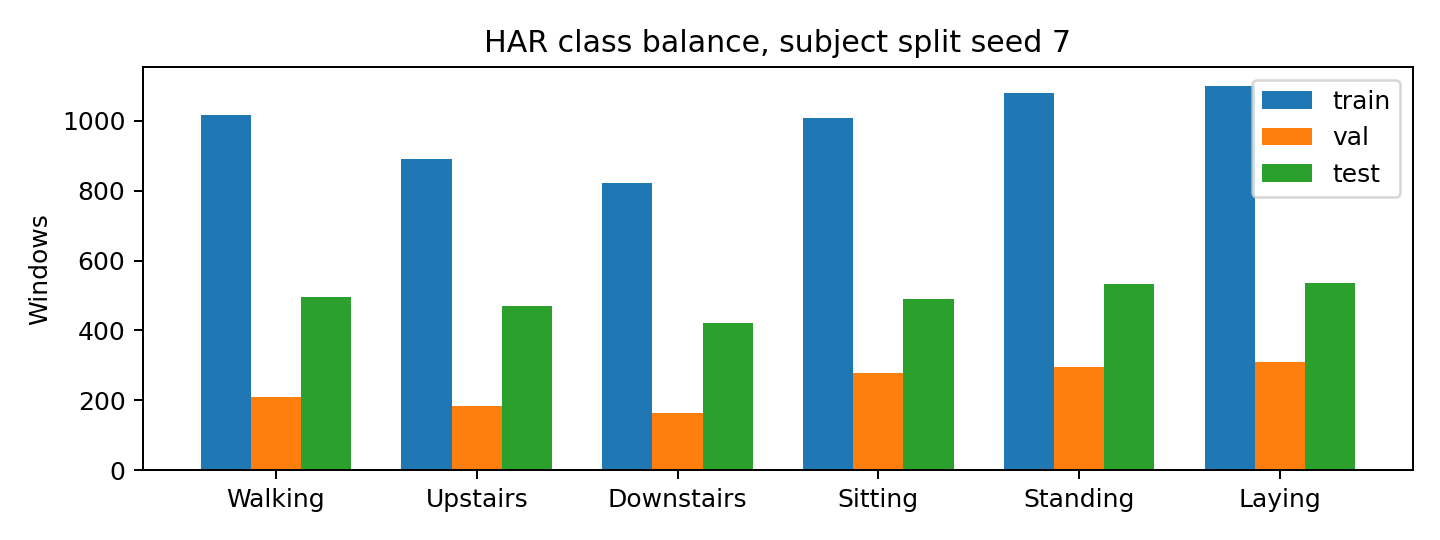

Figure 2. Validation-selected HAR confusion matrix.


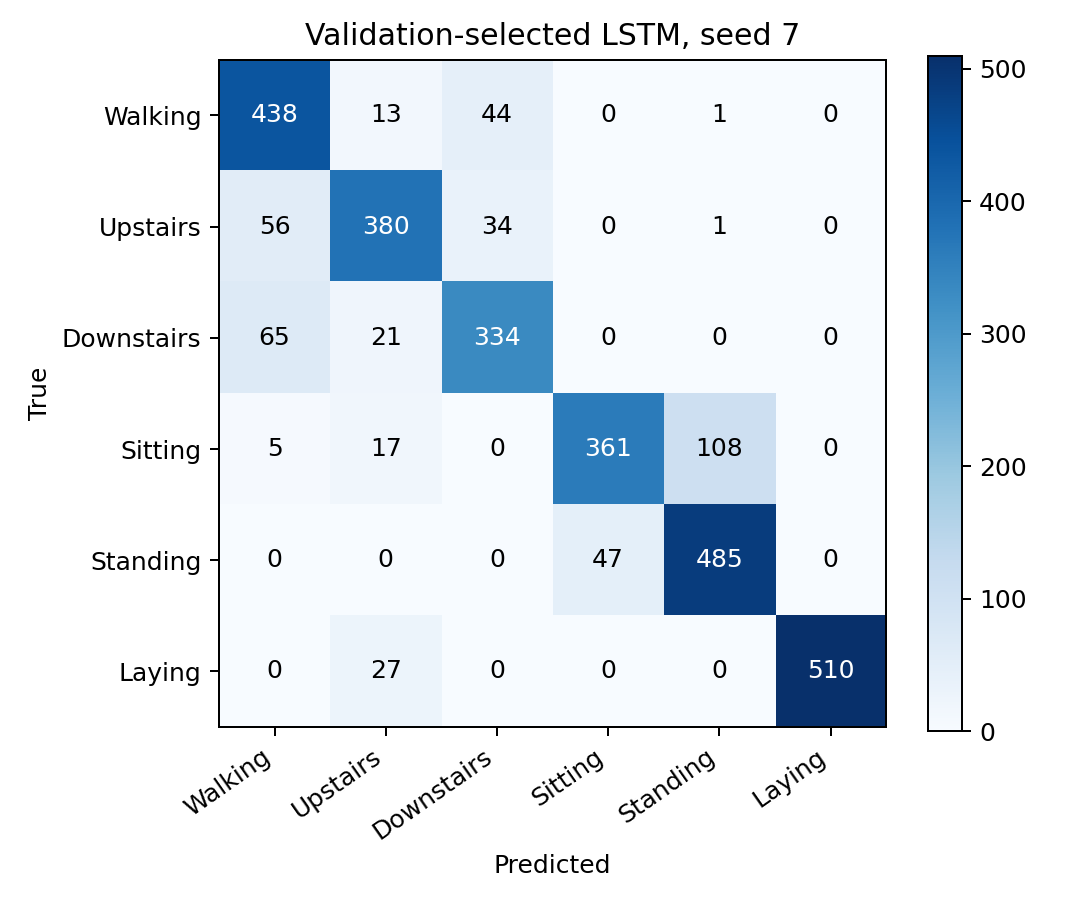

Figure 3. Adding test MSE versus length.


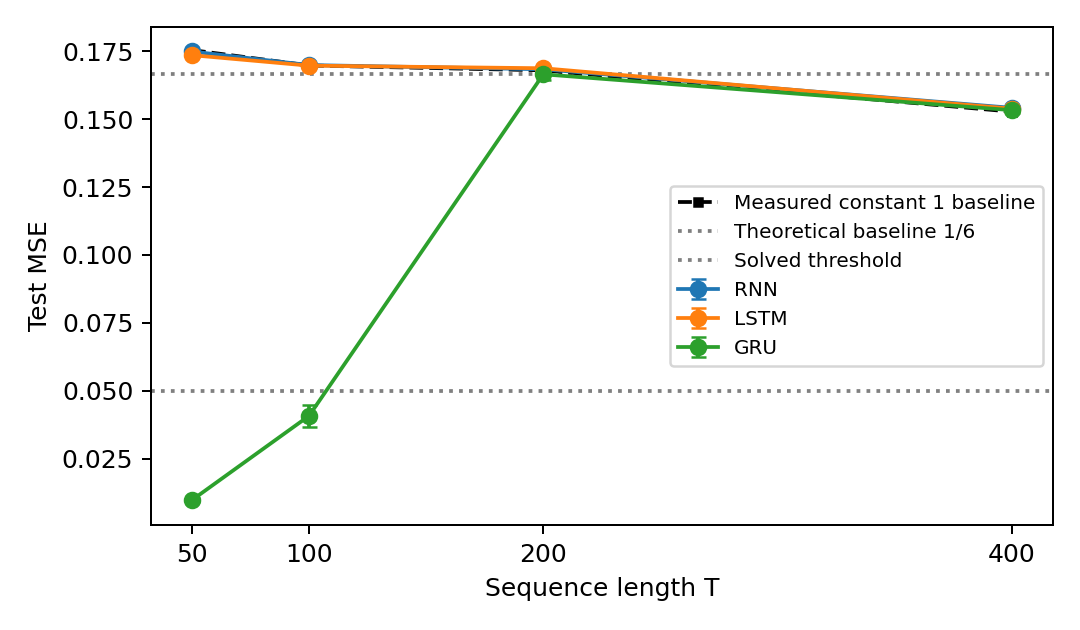

Figure 4. Adding curves at T=200.


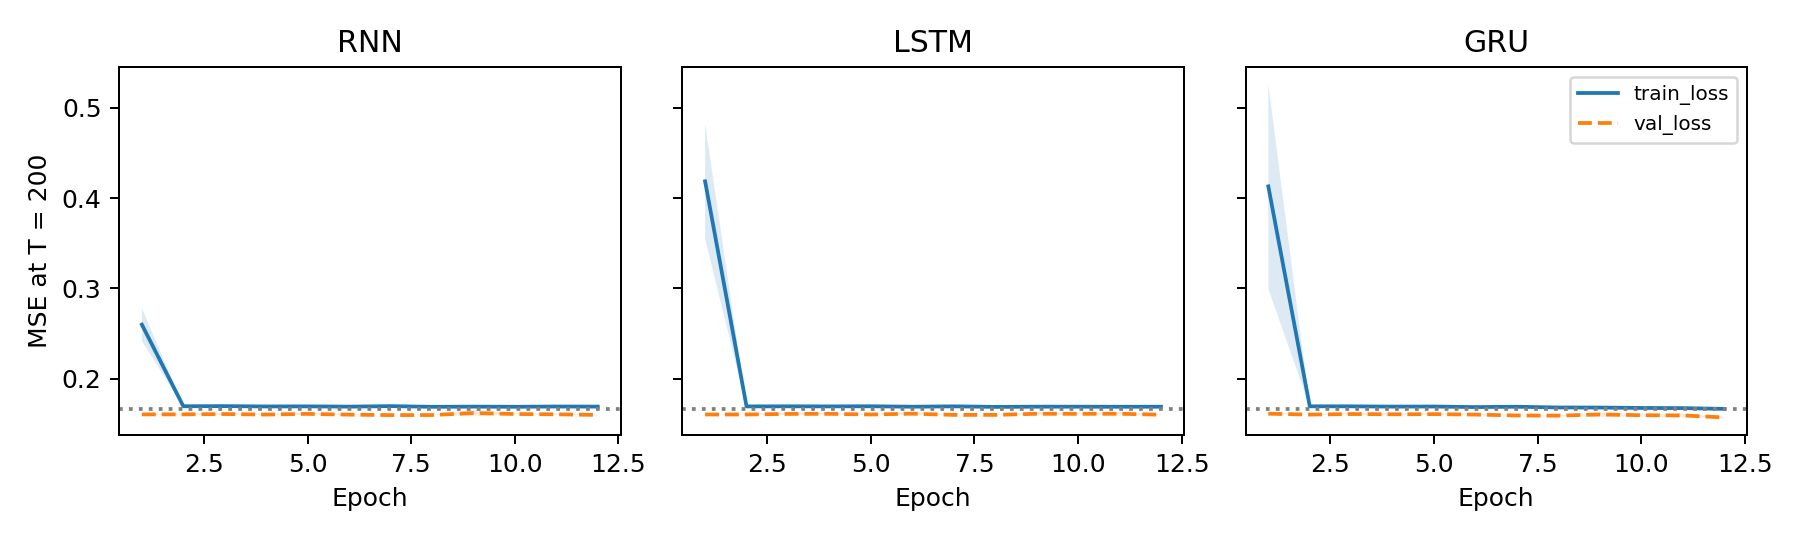

Figure 5. Hidden-state gradients at T=100.


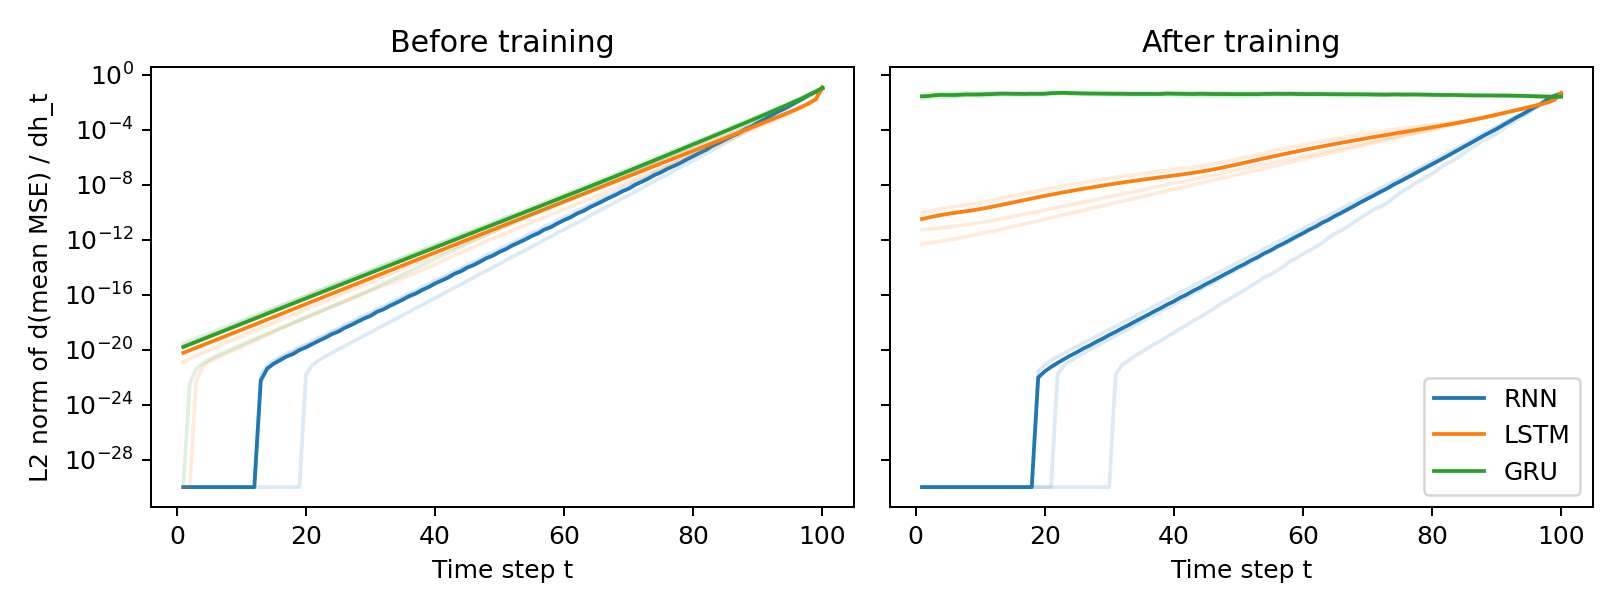

Figure 6. Hidden-size sweep.


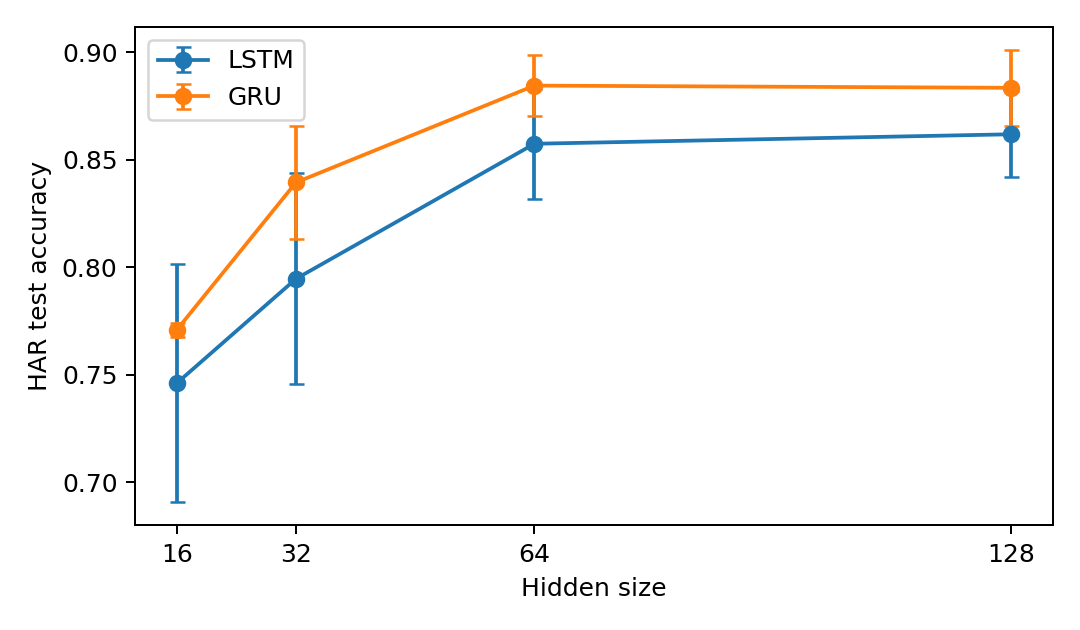

Figure 7. Clipping ablation.


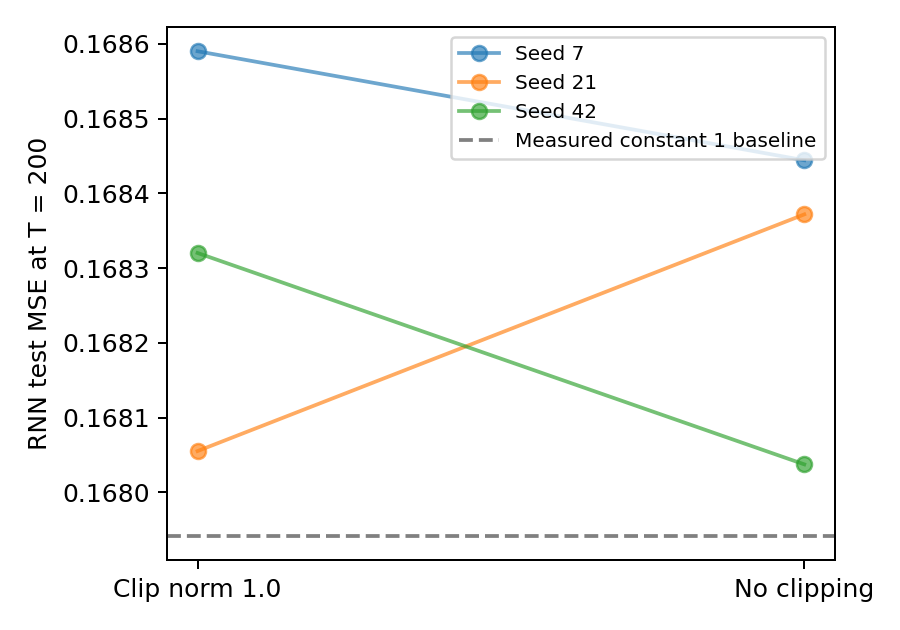

Notebook elapsed: 0.04 minutes. Runtime record: problem1/figures/notebook_runtime.json
This invocation allowed cached results; it is not a full-training benchmark.


In [43]:
figures = ROOT/'problem1/figures'
for filename, caption in [('class_balance_seed7.png', 'Figure 1. Class balance.'), ('best_har_confusion.png', 'Figure 2. Validation-selected HAR confusion matrix.'), ('adding_mse_vs_length.png', 'Figure 3. Adding test MSE versus length.'), ('adding_T200_learning_curves.png', 'Figure 4. Adding curves at T=200.'), ('hidden_gradients_T100.png', 'Figure 5. Hidden-state gradients at T=100.'), ('hidden_size_sweep.png', 'Figure 6. Hidden-size sweep.'), ('clipping_ablation_T200.png', 'Figure 7. Clipping ablation.')]:
    print(caption)
    display(Image(filename=str(figures/filename)))
finish_notebook_run()


## Save or transfer the completed run

**VS Code:** save the notebook with Cmd+S / Ctrl+S. **Colab:** download the executed notebook with File > Download > Download .ipynb. Then run `export_run_files()` in a new cell and upload that downloaded notebook when prompted; this saves its real outputs into the ZIP. After Problem 1, use that updated ZIP when Problem 2 setup asks for the assignment ZIP, so the two runs keep a combined results.csv. The two Colab tabs may have separate runtimes. Each problem records elapsed wall time in `figures/notebook_runtime.json`; only records with reuse disabled represent full retraining. Update the report if new measurements differ.
